# Cache Utility: анализ гранат на Cache

Все **2 385 417 бросков** из 10 000 исходных матчей учтены. Для HE и Молотова/зажигательной гранаты показывается записанный урон, для флешек — факт и величина ослепления, для смоков — геометрическое перекрытие линий обзора.

Поставляемая модель флешек — **HistGradientBoosting**: test ROC-AUC **0,7427**, balanced accuracy **0,6723**. Более строгий положительный порог даёт precision **0,8028 при охвате 0,4854**.

## Данные и метод

Единица наблюдения — один бросок. Из 10 000 матчей ([датасет](https://drive.google.com/file/d/1ZqNH0g4q79T8NngzeXHunzSztMv-XcCG/view)) 9 984 имеют гранаты, 16 пусты.
- Положительная метка флешки означает зарегистрированное добавление ослепления противнику; пропуск не считается нулём.
- `setup` использует 13 признаков состояния бросающего. `release` добавляет первую записанную позицию гранаты и предыдущие броски в раунде; после преобразований получается 33 признака. 
- События одного тика не включают друг друга. Конечная точка, записанный эффект, победа, выживание, ID и постматчевый рейтинг не становятся признаками.
- Выбор конфигурации и порогов использует только пять разбиений обучающих матчей (train). Отложенные матчи (test) не пересекаются с train.
- Для известных train-строк используются прогнозы вне обучавшей модель части (OOF), для test — отложенные прогнозы. Это относится к классификатору и обеим регрессиям. Рабочие модели обучены на всех известных исходах и отделены от моделей проверки.
- Единица `FlashDurationAdded` не установлена. Во всех бросках `StartProperVelocity = −PlayerVelocity`.


In [1]:
%matplotlib inline
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from IPython.display import Markdown, display
from scope_cache.core import sha256_file
from scope_cache.report import (
    STYLE, draw_availability, draw_map, draw_smoke, draw_model,
    draw_sampling, draw_selection, selection_table, uncertainty_table,
)

ROOT = Path.cwd()


def read(name):
    return json.loads((ROOT / name).read_text(encoding="utf-8"))


source = read("data/events.metadata.json")
model = read("models/flash.metadata.json")
analysis = read("reports/analysis.json")
diagnostics = analysis["model"]
smoke = analysis["smoke"]
checks = read("reports/checks.json")
validation = checks["audit"]
assert validation["ok"], "Run python scope.py audit"
assert diagnostics["model_sha256"] == model["artifact"]["sha256"]
assert sha256_file(ROOT / "models/flash.joblib") == model["artifact"]["sha256"]
assert sha256_file(ROOT / "models/flash.validation.parquet") == model["predictions_sha256"]


def show(figure):
    display(figure)
    plt.close(figure)


assert sha256_file(ROOT / "data/events.parquet") == model["source"]["events_sha256"]
assert sha256_file(ROOT / "data/release_context.parquet") == model["source"]["context_sha256"]
score_metadata = read("data/grenade_scores.metadata.json")
assert score_metadata["model_sha256"] == model["artifact"]["sha256"]
assert sha256_file(ROOT / "data/grenade_scores.parquet") == score_metadata["scores_sha256"]

ModuleNotFoundError: No module named 'awpy'

## 1. Полнота исходов

Все броски сохранены. Известный нулевой эффект отличается от неизвестного. У смока метка реального перекрытия обзора отсутствует, т.к. доля «успешных смоков» из источника не выводится.

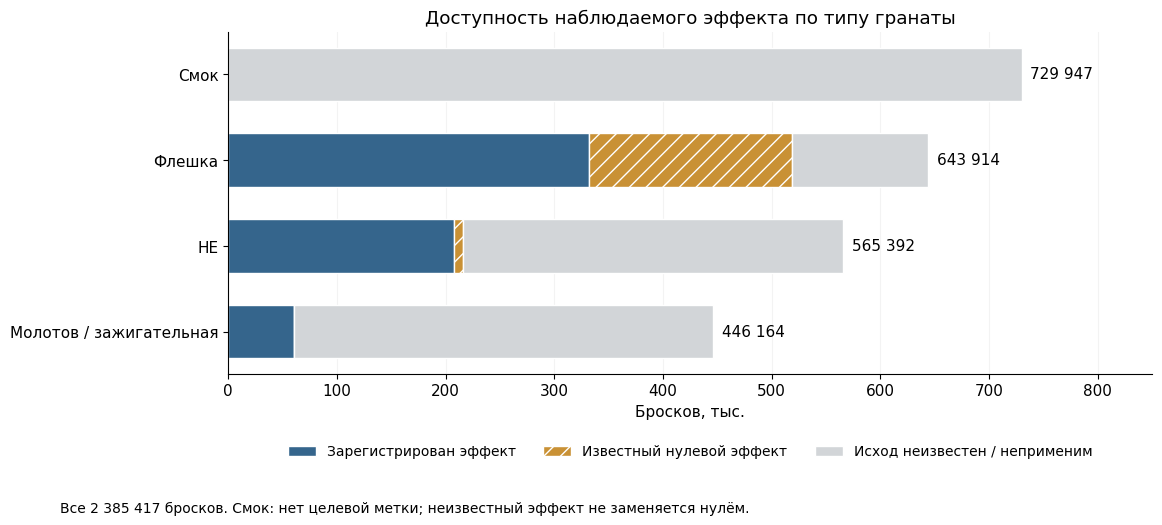

In [ ]:
with plt.rc_context(STYLE):
    show(draw_availability(source))

In [ ]:
missing = diagnostics["missingness"]
lo, hi = missing["registered_effect_rate_bounds"]
display(
    Markdown(
        f"Доля известных исходов флешек: **{missing['known_fraction']:.1%}**. "
        f"Наличие метки предсказывается на test с ROC-AUC **{missing['registration_prediction_test']['roc_auc']:.3f}**. "
        f"Без предположений о пропусках доля положительных среди всех ограничена **{lo:.1%}–{hi:.1%}**. "
        "Предсказуемая регистрация указывает на различия популяций; MAR и причинная коррекция не предполагаются."
    )
)

Доля известных исходов флешек: **80.6%**. Наличие метки предсказывается на test с ROC-AUC **0.690**. Без предположений о пропусках доля положительных среди всех ограничена **51.6%–71.0%**. Предсказуемая регистрация указывает на различия популяций; MAR и причинная коррекция не предполагаются.

## 2. Трёхмерная геометрия Cache

[Закреплённые файлы карты](https://github.com/pnxenopoulos/awpy-data/releases/tag/2000934): CS2 client 2000934, patch 1.41.9.1. Проверка стен использует все 338 375 треугольников поставляемого mesh. Из 2 209 областей navmesh выбраны 715 точек; свободными остаются 18 022 отрезка длиной 128–1 600 Hammer units.

Это выборка линий обзора между точками карты. Они не объявляются фактическими взглядами игроков, скорее их стоит воспринимать как примерный набросок

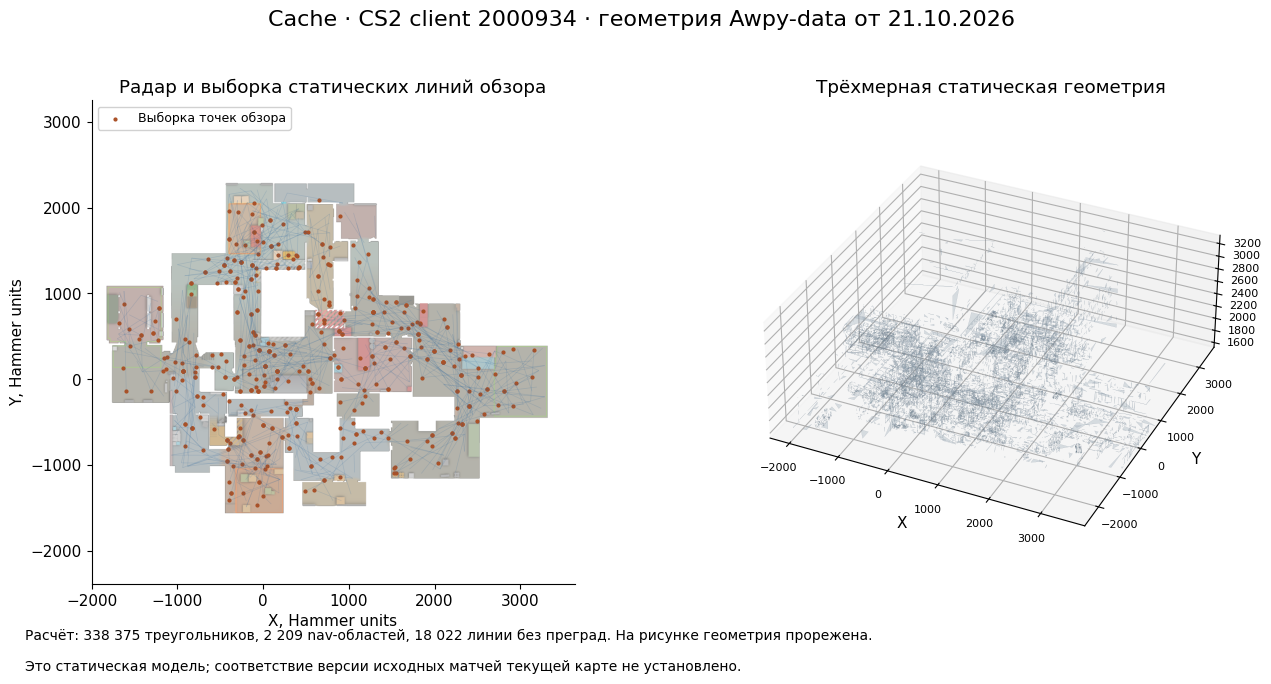

In [ ]:
with plt.rc_context(STYLE):
    show(draw_map())

## 3. Смок: геометрическое перекрытие линий обзора

Метрика — доля свободных от стен линий в локальном контексте, пересекающих предполагаемый объём дыма минимум на 32 Hammer units. Линии имеют равный вес. Базовый эллипсоид: радиус XY 144, Z 96, центр на 72 выше точки раскрытия смока, локальный радиус 450. Это допущения о форме дыма.

При массовом расчёте точки раскрытия дыма округляются к 16 единицам; для одного смока используются точные координаты. Радиусы 96/144/192 — сценарии чувствительности, а не доверительные границы. Нулевой знаменатель оставляет показатель неизвестным.

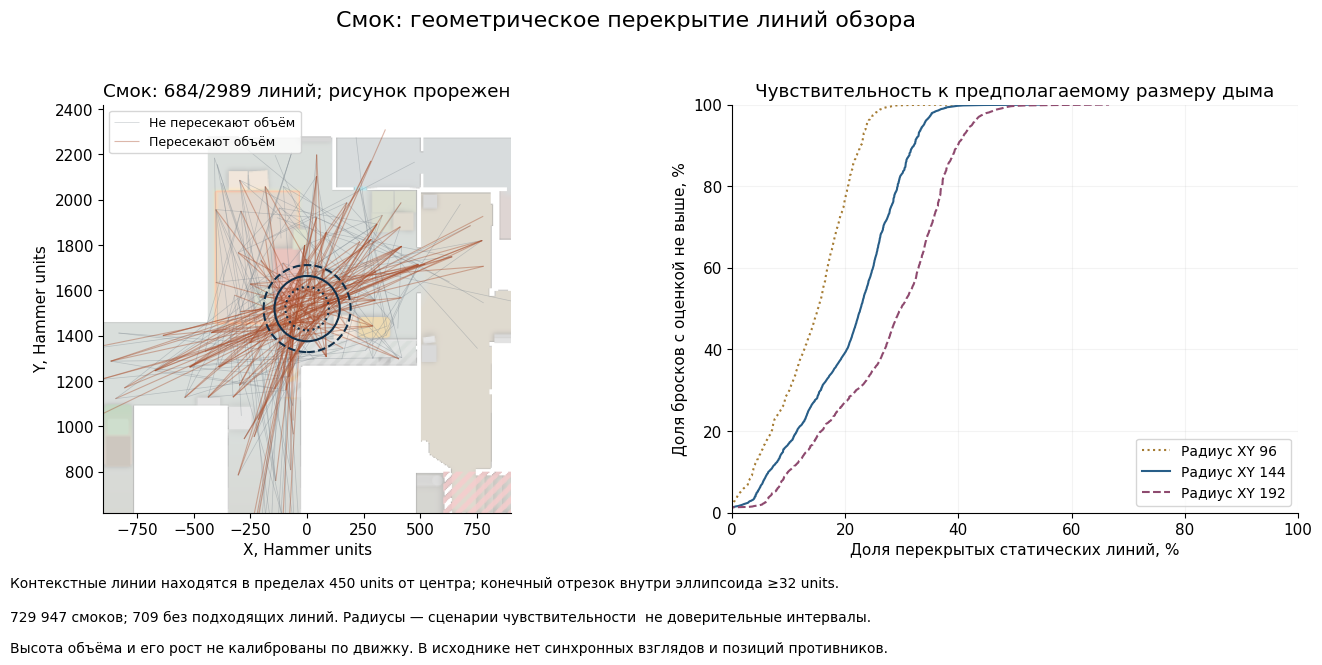

In [ ]:
with plt.rc_context(STYLE):
    show(draw_smoke())

Чувствительность к плотности точек обзора проверена на 2 000 случайных занятых ячеек точек детонации с равными весами, seed 817. Сравниваются сетки XY 64/128/256 units при одном радиусе дыма. Неизвестные результаты исключаются попарно; частота популярных раскидок не задаёт вес ячейки.

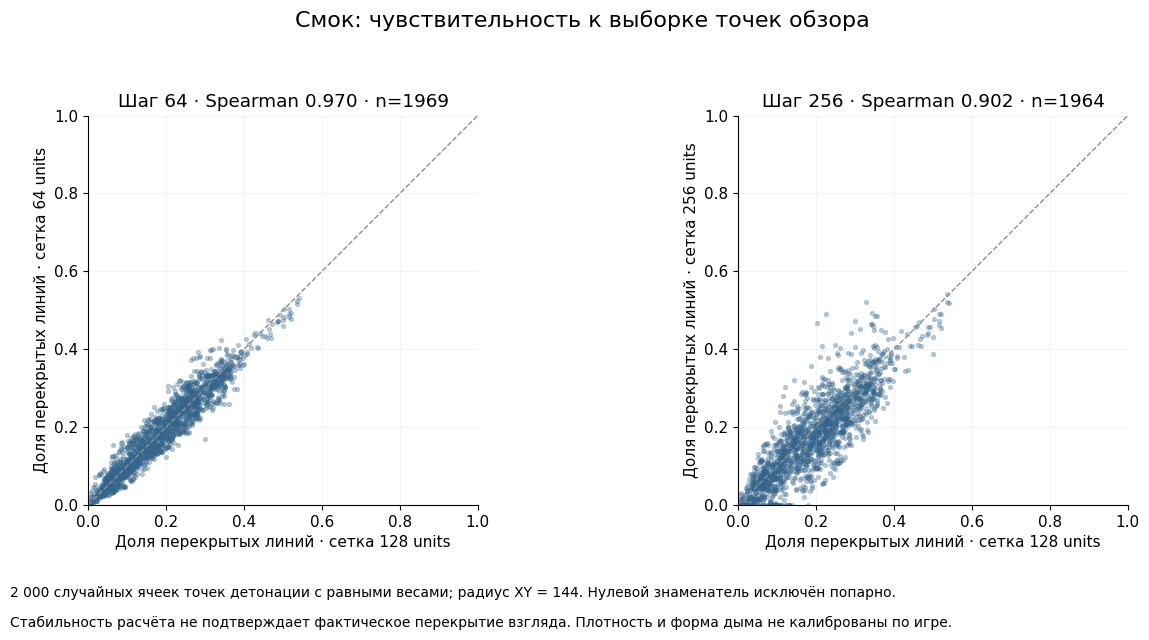

Независимый алгоритм пересечений по всем треугольникам совпал с BVH для **32 лучей**. Для **98.4%** точек детонации смока расстояние до центра ближайшей nav-области ≤128 units. Это проверка координат; она не доказывает попадание в границы доступной области или совпадение сборки карты. **Фактическое перекрытие обзора противника не подтверждено.**

In [ ]:
with plt.rc_context(STYLE):
    show(draw_sampling(smoke))
ray = smoke["independent_ray_validation"]
align = smoke["coordinate_alignment"]
display(Markdown(
    f"Независимый алгоритм пересечений по всем треугольникам совпал с BVH для **{ray['rays']} лучей**. "
    f"Для **{align['fraction_within_128_units']:.1%}** точек детонации смока расстояние до центра ближайшей nav-области ≤128 units. "
    "Это проверка координат; она не доказывает попадание в границы доступной области или совпадение сборки карты. "
    "**Фактическое перекрытие обзора противника не подтверждено.**"
))

Геометрический показатель не учитывает сторону, важность направления и время действия. Смок может закрыть союзников. Форма, плотность, рост дыма, отверстия от пуль/HE, динамические двери и визуальное обнаружение не проверены по игровому изображению. `actual_enemy_view_blocked` в исходных данных остаётся `null`.

## 4. Модель флешек и вклад контекста броска

Шесть фиксированных конфигураций сравниваются на одном train. Критерий — OOF log loss. Проверены логистическая регрессия, дерево решений, HGB, CatBoost и приближённая RBF-модель; отдельно сохранён CatBoost с входом `setup`. HGB с контекстом броска выиграл это сравнение. Глобальный оптимум алгоритма не утверждается.

| Кандидат | Train OOF log loss | Train OOF ROC-AUC |
|---|---:|---:|
| release_hist | 0.559533 | 0.7435 |
| release_catboost | 0.565304 | 0.7374 |
| setup_catboost | 0.578656 | 0.7191 |
| release_tree | 0.603636 | 0.6706 |
| release_rbf | 0.612983 | 0.6655 |
| release_logistic | 0.626841 | 0.6368 |

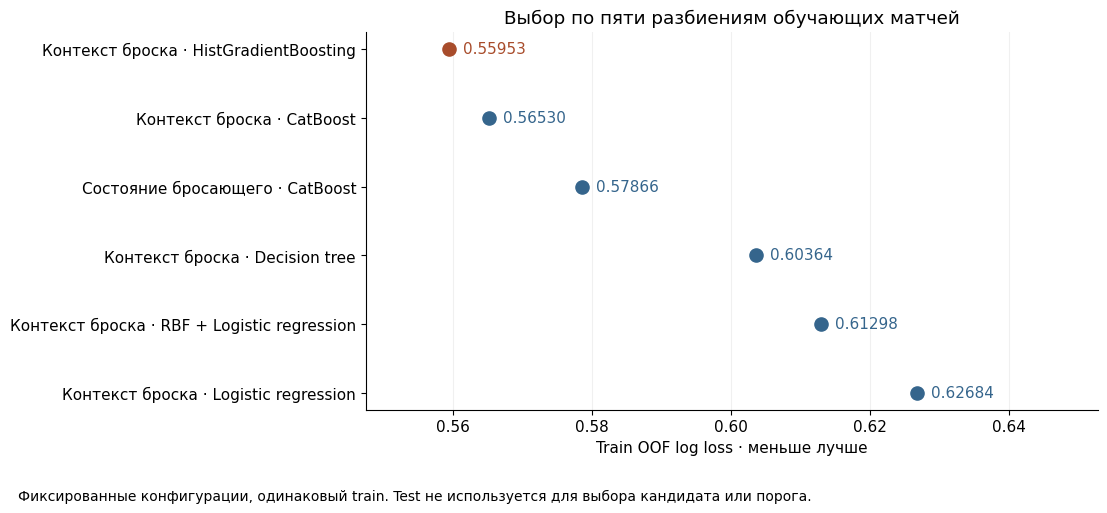

**Одинаковая сложность HGB, разные входы:** train OOF log loss 0.571877 → 0.559533; test ROC-AUC 0.7264 → 0.7427. Это диагностическая абляция, test не использован для дальнейшего подбора.

In [ ]:
display(Markdown(selection_table(model)))
with plt.rc_context(STYLE):
    show(draw_selection(model))
ablation = diagnostics["same_capacity_information_ablation"]
display(
    Markdown(
        f"**Одинаковая сложность HGB, разные входы:** train OOF log loss "
        f"{ablation['setup_oof']['log_loss']:.6f} → {ablation['release_oof']['log_loss']:.6f}; "
        f"test ROC-AUC {ablation['setup_test']['roc_auc']:.4f} → {ablation['release_test']['roc_auc']:.4f}. "
        "Это диагностическая абляция, test не использован для дальнейшего подбора."
    )
)

## 5. Отложенные матчи: разделение классов и калибровка

Test содержит 104 238 известных исходов флешек из 1 994 матчей. 95% интервалы рассчитаны по 300 пересэмплированиям целых матчей, seed 714. Метрики взвешены бросками. Интервалы отражают вариацию между матчами, а не гарантии качества в другой сборке игры.

| Метрика test | Оценка | 95% интервал по матчам |
|---|---:|---:|
| roc_auc | 0.7427 | 0.7395–0.7461 |
| average_precision | 0.8300 | 0.8265–0.8340 |
| accuracy | 0.6786 | 0.6753–0.6822 |
| balanced_accuracy | 0.6723 | 0.6693–0.6756 |
| brier | 0.1903 | 0.1889–0.1916 |
| log_loss | 0.5601 | 0.5568–0.5631 |

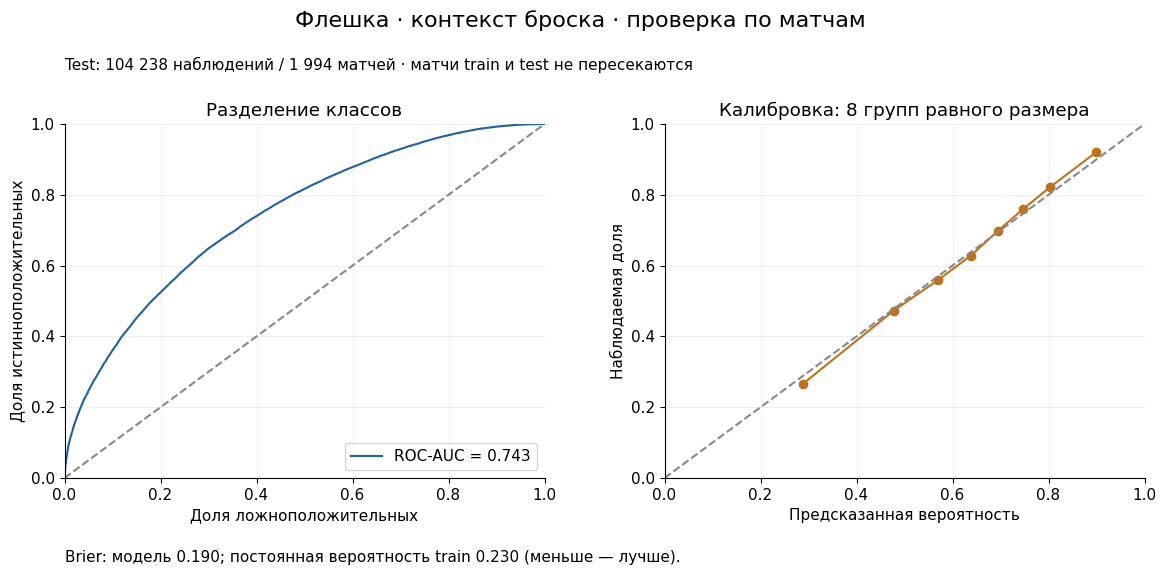

In [ ]:
display(Markdown(uncertainty_table(diagnostics)))
records = (
    pq.read_table(
        ROOT / "models/flash.validation.parquet",
        filters=[("partition", "=", "test")],
        columns=["partition", "impact", "probability"],
    )
    .rename_columns(["partition", "label", "probability"])
    .to_pylist()
)
with plt.rc_context(STYLE):
    show(
        draw_model(
            dict(model, baseline=model["baseline_constant"]),
            records,
            "Флешка · контекст броска · проверка по матчам",
        )
    )

In [ ]:
point = diagnostics["selective_positive"]
ci = point["precision_ci95"]
plain = model["test"]["metrics_at_0_5"]
test = model["test"]["metrics"]
display(
    Markdown(
        f"Основной порог train OOF: **{model['decision_threshold']:.5f}**. "
        f"Accuracy **{test['accuracy']:.4f}**, balanced accuracy **{test['balanced_accuracy']:.4f}**. "
        f"При 0,5: accuracy {plain['accuracy']:.4f}, balanced accuracy {plain['balanced_accuracy']:.4f}. "
        f"Постоянное положительное решение: accuracy {model['test']['prevalence']:.4f}.\n\n"
        f"Строгий положительный порог **{point['threshold']:.5f}**: "
        f"precision **{point['precision']:.1%}** (95% CI {ci[0]:.1%}–{ci[1]:.1%}), "
        f"**охват {point['coverage']:.1%}**, recall {point['recall']:.1%}. "
        "Порог выбран на train OOF; гарантии 80% precision на будущих данных нет."
    )
)
rows = ["| Срез test | Строк | ROC-AUC | Balanced accuracy |", "|---|---:|---:|---:|"]
for row in diagnostics["slices"]:
    if row["slice"] in ["T", "CT", "unseen_thrower", "seen_thrower"]:
        m = row["metrics"]
        rows.append(
            f"| {row['slice']} | {row['rows']:,} | {m['roc_auc']:.4f} | {m['balanced_accuracy']:.4f} |"
        )
display(Markdown("\n".join(rows)))

Основной порог train OOF: **0.63452**. Accuracy **0.6786**, balanced accuracy **0.6723**. При 0,5: accuracy 0.7062, balanced accuracy 0.6359. Постоянное положительное решение: accuracy 0.6405.

Строгий положительный порог **0.67397**: precision **80.3%** (95% CI 79.9%–80.6%), **охват 48.5%**, recall 60.8%. Порог выбран на train OOF; гарантии 80% precision на будущих данных нет.

| Срез test | Строк | ROC-AUC | Balanced accuracy |
|---|---:|---:|---:|
| T | 60,708 | 0.7585 | 0.6736 |
| CT | 43,530 | 0.7000 | 0.6383 |
| unseen_thrower | 90,039 | 0.7444 | 0.6739 |
| seen_thrower | 14,199 | 0.7321 | 0.6627 |

Качество T и CT различается: общий результат не означает одинакового качества на обеих сторонах. 90 039 test-бросков сделаны игроками, которых нет среди бросающих в train; это диагностический срез, не строгое разбиение по всем участникам матча и не временная проверка.

## 6. Величина ослепления и показатели игроков

Две регрессии обучены на положительных исходах. Ожидаемая величина равна вероятности положительного эффекта, умноженной на условное среднее. Положительная оценка количества ослеплённых ограничена 1–5. Все известные train/test-строки имеют OOF/отложенные прогнозы.

Базовое сравнение для регрессии — постоянное среднее train; для условной величины — среднее положительных train. `FlashDurationAdded` сохраняет единицы источника.

In [ ]:
rows = [
    "| Цель | Test MAE | MAE константы | Test RMSE | RMSE константы |",
    "|---|---:|---:|---:|---:|",
]
labels = {
    "conditional_flash_added": "Величина ослепления при положительном исходе",
    "expected_flash_added": "Ожидаемая величина ослепления",
    "expected_blinded_players": "Ожидаемое число ослеплённых противников",
}
for key in labels:
    r = model["severity"][key]
    rows.append(
        f"| {labels[key]} | {r['mae']:.4f} | {r['baseline_mae']:.4f} | {r['rmse']:.4f} | {r['baseline_rmse']:.4f} |"
    )
display(Markdown("\n".join(rows)))
profile = analysis["players"]
display(
    Markdown(
        f"**Профили:** {profile['players_with_recorded_throws']:,} игроков; "
        f"только **{profile['eligible_flash_estimates']}** проходят критерий ≥50 известных флешек, ≥5 матчей "
        "и ≤50% из одного матча. Для остальных нет интервала отклонения флешек от прогноза. "
        "Остаток — среднее (факт − OOF/test вероятность), не общий КПД и не причинный вклад. "
        "HP, число ослеплённых, FlashDurationAdded и перекрытие линий обзора не складываются."
    )
)

| Цель | Test MAE | MAE константы | Test RMSE | RMSE константы |
|---|---:|---:|---:|---:|
| Величина ослепления при положительном исходе | 2.0291 | 2.1088 | 2.7066 | 2.8648 |
| Ожидаемая величина ослепления | 2.0753 | 2.3434 | 2.7173 | 2.9244 |
| Ожидаемое число ослеплённых противников | 0.6329 | 0.6700 | 0.8342 | 0.9088 |

**Профили:** 89,052 игроков; только **34** проходят критерий ≥50 известных флешек, ≥5 матчей и ≤50% из одного матча. Для остальных нет интервала отклонения флешек от прогноза. Остаток — среднее (факт − OOF/test вероятность), не общий КПД и не причинный вклад. HP, число ослеплённых, FlashDurationAdded и перекрытие линий обзора не складываются.

## 7. Демо и дальнейшая проверка

Единая команда принимает `.dem` через demoparser2 либо CS-NET `cs2.demo.v2`. Сохраняются точные ID, границы раундов, выживание, победитель, урон, позиции и записанные владелец/время жизни смока. Смерти после round_end исключены. Float-ID отклоняются; конверсия в account32 выполняется только явно. Ошибка не оставляет частичный импорт.

```bash
python -m pip install -e ".[demo]"
python scope.py demo --input MATCH.dem --output demo_context --match-id EXACT_MATCH_ID --expected-map de_cache --score-smokes
```

При синхронной телеметрии рассчитывается время геометрического перекрытия обзора противника по направленным парам «наблюдатель — цель». Учитываются стены, направление взгляда, интервалы и дополнительное перекрытие при наложении смоков. Высота глаз, поле зрения и объём дыма остаются допущениями. Известное несовпадение патча блокирует геометрию. Связь с исходными бросками требует точного совпадения ID матча/игрока/раунда; имена и похожие координаты не используются.

In [ ]:
integration = analysis["demo_import"]
display(Markdown(
    f"Импорт настоящего **.dem** проверен: **{integration['map']}**, "
    f"{integration['rounds']} раундов, {integration['player_rounds']} результатов игроков, "
    f"{integration['alive_end_known']} известных исходов выживания и "
    f"{integration['smokes_with_recorded_owner']} смоков с записанным владельцем. "
    "Демо использована для проверки импорта; её данные не добавлены в модель Cache. "
    "Соответствующих исходным Cache-матчам демо и проверки видимости по игровому изображению нет."
))
test_status = "PASS" if checks["unit_tests"]["ok"] else "FAIL"
display(Markdown(
    f"**Проверок полного набора: {validation['counts']['checks']}**, PASS. "
    f"Бросков: {validation['counts']['events']:,}. "
    f"**Тестов кода: {checks['unit_tests']['tests_run']}**, {test_status}."
))

Импорт настоящего **.dem** проверен: **de_mirage**, 10 раундов, 99 результатов игроков, 99 известных исходов выживания и 40 смоков с записанным владельцем. Демо использована для проверки импорта; её данные не добавлены в модель Cache. Соответствующих исходным Cache-матчам демо и проверки видимости по игровому изображению нет.

**Проверок полного набора: 44**, PASS. Бросков: 2,385,417. **Тестов кода: 32**, PASS.

## Границы выводов

Проект воспроизводимо учитывает все исходные броски, отделяет записанный эффект от неизвестного, прогнозирует ослепление и вычисляет геометрическое перекрытие линий обзора смоками. Есть рабочий импорт телеметрии из демо.

Для проверки переноса нужен новый заранее отложенный набор Cache-демо с известной сборкой. Фактическое перекрытие обзора требует синхронных данных и проверки по игровому изображению. Даже связь с победой или выживанием не доказывает причинный импакт одной гранаты.

Подробности: `README_CONCEPT.md`, `README_TECHNICAL.md`; протокол модели — `models/flash.metadata.json`.